# Phase 03 — Psychological Capital → Employability

## Step 02 — Reliability Analysis

This notebook evaluates the internal consistency of the Psychological Capital and Employability questionnaire scales before statistical modelling and machine-learning experiments.

The analysis includes:

- Cronbach's Alpha
- Corrected Item–Total Correlation
- Cronbach's Alpha if Item Deleted
- Inter-item Correlation
- Bootstrap confidence intervals for Cronbach's Alpha
- Reliability classification and validation

Reliability is evaluated for the four Psychological Capital constructs:

- Hope
- Optimism
- Resilience
- Self-Efficacy

Overall Psychological Capital and Employability reliability are also evaluated.

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "phase3_psycap":
    PROJECT_DIR = PROJECT_DIR.parent.parent

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "phase3_psycap_prepared.csv"
)

REPORT_DIR = (
    PROJECT_DIR
    / "reports"
    / "phase3"
    / "reliability"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("PROJECT_DIR:", PROJECT_DIR)
print("DATA_PATH:", DATA_PATH)
print("REPORT_DIR:", REPORT_DIR)

PROJECT_DIR: d:\internship-employability-project
DATA_PATH: d:\internship-employability-project\data\processed\phase3_psycap_prepared.csv
REPORT_DIR: d:\internship-employability-project\reports\phase3\reliability


In [6]:
df = pd.read_csv(
    DATA_PATH
)

print(
    "Dataset shape:",
    df.shape
)

df.head()

Dataset shape: (1000, 41)


,Response_ID,Gender,Age,Degree Program,Internship Status,PsyCap1,PsyCap2,PsyCap3,PsyCap4,PsyCap5,...,Optimism_avg,Resilience_avg,SelfEfficacy_avg,PsyCap_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg,EVS_avg
0,1,Female,18–20,Information Technology,Yes,5,4,4,4,5,...,4.333333,4.000000,3.666667,4.083333,5.000000,4.0,4.75,5.0,5.0,4.750000
1,2,Female,21–23,Business Management,Yes,3,5,5,4,4,...,4.000000,3.666667,3.666667,3.916667,3.666667,3.5,3.75,4.0,2.5,3.500000
2,3,Male,18–20,Information Technology,Yes,4,5,4,5,4,...,4.333333,3.333333,3.333333,3.833333,3.666667,4.0,3.75,4.0,3.5,3.750000
3,4,Male,18–20,Engineering,Yes,4,4,4,4,4,...,4.000000,4.000000,4.000000,4.000000,4.000000,4.0,4.00,4.0,4.0,4.000000
4,5,Male,21–23,Business Management,Yes,3,3,5,3,5,...,4.000000,3.666667,3.333333,3.666667,4.000000,4.5,4.50,5.0,4.0,4.333333


## Construct Definitions

Psychological Capital is represented by four theoretically defined dimensions.

The final 12-item structure used in this study is:

- Hope: PsyCap1–PsyCap3
- Optimism: PsyCap4–PsyCap6
- Resilience: PsyCap7–PsyCap9
- Self-Efficacy: PsyCap10–PsyCap12

Employability is represented using EVS1–EVS12.

Define Item Groups

In [7]:
PSYCAP_CONSTRUCTS = {

    "Hope": [
        "PsyCap1",
        "PsyCap2",
        "PsyCap3"
    ],

    "Optimism": [
        "PsyCap4",
        "PsyCap5",
        "PsyCap6"
    ],

    "Resilience": [
        "PsyCap7",
        "PsyCap8",
        "PsyCap9"
    ],

    "Self-Efficacy": [
        "PsyCap10",
        "PsyCap11",
        "PsyCap12"
    ]
}


PSYCAP_ITEMS = [
    item
    for items in PSYCAP_CONSTRUCTS.values()
    for item in items
]


EVS_CONSTRUCTS = {

    "Human Capital": [
        "EVS1",
        "EVS2",
        "EVS3"
    ],

    "Social Capital": [
        "EVS4",
        "EVS5"
    ],

    "Career Identity": [
        "EVS6",
        "EVS7",
        "EVS8",
        "EVS9"
    ],

    "Environmental Monitoring": [
        "EVS10"
    ],

    "Balance": [
        "EVS11",
        "EVS12"
    ]
}


EVS_ITEMS = [
    f"EVS{i}"
    for i in range(1, 13)
]

Validate Required Reliability Columns

In [8]:
required_items = (
    PSYCAP_ITEMS
    +
    EVS_ITEMS
)

missing_items = [
    item
    for item in required_items
    if item not in df.columns
]

if missing_items:
    raise ValueError(
        f"Missing questionnaire items: {missing_items}"
    )

print(
    "All required questionnaire items are available."
)

All required questionnaire items are available.


Cronbach's Alpha Function

In [9]:
def cronbach_alpha(data):

    data = data.dropna()

    item_scores = (
        data
        .astype(float)
    )

    number_of_items = (
        item_scores.shape[1]
    )

    if number_of_items < 2:
        return np.nan

    item_variances = (
        item_scores
        .var(
            axis=0,
            ddof=1
        )
        .sum()
    )

    total_score = (
        item_scores
        .sum(
            axis=1
        )
    )

    total_variance = (
        total_score
        .var(
            ddof=1
        )
    )

    if total_variance == 0:
        return np.nan

    alpha = (
        number_of_items
        /
        (
            number_of_items
            - 1
        )
    ) * (
        1
        -
        (
            item_variances
            /
            total_variance
        )
    )

    return float(alpha)

Cronbach’s Alpha කියන්නේ items කිහිපයක් එකම underlying concept එක consistently measure කරනවද කියලා බලන reliability statistic එක.

Reliability Interpretation Function

In [10]:
def interpret_alpha(alpha):

    if pd.isna(alpha):
        return "Not Applicable"

    if alpha >= 0.90:
        return "Excellent"

    elif alpha >= 0.80:
        return "Good"

    elif alpha >= 0.70:
        return "Acceptable"

    elif alpha >= 0.60:
        return "Questionable"

    elif alpha >= 0.50:
        return "Poor"

    else:
        return "Unacceptable"

Calculate PsyCap Construct Reliability

In [11]:
psycap_reliability_results = []

for construct, items in (
    PSYCAP_CONSTRUCTS.items()
):

    alpha = cronbach_alpha(
        df[items]
    )

    psycap_reliability_results.append({

        "Construct": construct,

        "Number_of_Items": len(
            items
        ),

        "Cronbach_Alpha": alpha,

        "Interpretation": (
            interpret_alpha(
                alpha
            )
        )
    })


psycap_reliability_df = pd.DataFrame(
    psycap_reliability_results
)

psycap_reliability_df

,Construct,Number_of_Items,Cronbach_Alpha,Interpretation
0,Hope,3,0.664161,Questionable
1,Optimism,3,0.722843,Acceptable
2,Resilience,3,0.661146,Questionable
3,Self-Efficacy,3,0.701764,Acceptable


Overall PsyCap Reliability

In [12]:
overall_psycap_alpha = cronbach_alpha(
    df[PSYCAP_ITEMS]
)

print(
    "Overall PsyCap Cronbach's Alpha:",
    overall_psycap_alpha
)

print(
    "Interpretation:",
    interpret_alpha(
        overall_psycap_alpha
    )
)

Overall PsyCap Cronbach's Alpha: 0.8945267747693746
Interpretation: Good


EVS Reliability

In [13]:
overall_evs_alpha = cronbach_alpha(
    df[EVS_ITEMS]
)

print(
    "Overall Employability Cronbach's Alpha:",
    overall_evs_alpha
)

print(
    "Interpretation:",
    interpret_alpha(
        overall_evs_alpha
    )
)

Overall Employability Cronbach's Alpha: 0.9002290457417935
Interpretation: Excellent


EVS Subconstruct Reliability

In [14]:
evs_reliability_results = []

for construct, items in (
    EVS_CONSTRUCTS.items()
):

    if len(items) < 2:

        evs_reliability_results.append({

            "Construct": construct,

            "Number_of_Items": len(
                items
            ),

            "Cronbach_Alpha": np.nan,

            "Interpretation": (
                "Single-item construct"
            )
        })

        continue


    alpha = cronbach_alpha(
        df[items]
    )

    evs_reliability_results.append({

        "Construct": construct,

        "Number_of_Items": len(
            items
        ),

        "Cronbach_Alpha": alpha,

        "Interpretation": (
            interpret_alpha(
                alpha
            )
        )
    })


evs_reliability_df = pd.DataFrame(
    evs_reliability_results
)

evs_reliability_df

,Construct,Number_of_Items,Cronbach_Alpha,Interpretation
0,Human Capital,3,0.724824,Acceptable
1,Social Capital,2,0.687016,Questionable
2,Career Identity,4,0.886500,Good
3,Environmental Monitoring,1,NaN,Single-item construct
4,Balance,2,0.888930,Good


Combined Reliability Summary

In [15]:
overall_rows = pd.DataFrame([
    {
        "Construct": (
            "Overall Psychological Capital"
        ),

        "Number_of_Items": len(
            PSYCAP_ITEMS
        ),

        "Cronbach_Alpha": (
            overall_psycap_alpha
        ),

        "Interpretation": (
            interpret_alpha(
                overall_psycap_alpha
            )
        )
    },

    {
        "Construct": (
            "Overall Employability"
        ),

        "Number_of_Items": len(
            EVS_ITEMS
        ),

        "Cronbach_Alpha": (
            overall_evs_alpha
        ),

        "Interpretation": (
            interpret_alpha(
                overall_evs_alpha
            )
        )
    }
])


reliability_summary = pd.concat(
    [
        psycap_reliability_df,
        evs_reliability_df,
        overall_rows
    ],
    ignore_index=True
)

reliability_summary

,Construct,Number_of_Items,Cronbach_Alpha,Interpretation
0,Hope,3,0.664161,Questionable
1,Optimism,3,0.722843,Acceptable
2,Resilience,3,0.661146,Questionable
3,Self-Efficacy,3,0.701764,Acceptable
4,Human Capital,3,0.724824,Acceptable
5,Social Capital,2,0.687016,Questionable
6,Career Identity,4,0.886500,Good
7,Environmental Monitoring,1,NaN,Single-item construct
8,Balance,2,0.888930,Good
9,Overall Psychological Capital,12,0.894527,Good


## Corrected Item–Total Correlation

Corrected item–total correlation evaluates how strongly each questionnaire item is associated with the total score of the remaining items in its construct.

Higher positive correlations generally indicate that an item is consistent with the construct it is intended to measure.

This statistic is used as a diagnostic measure and is interpreted together with theoretical relevance and Cronbach's Alpha.

Corrected Item-Total Correlation Function

In [16]:
def corrected_item_total_correlations(
    data
):

    results = []

    for item in data.columns:

        remaining_items = (
            data
            .drop(
                columns=[item]
            )
        )

        remaining_total = (
            remaining_items
            .sum(
                axis=1
            )
        )

        correlation = (
            data[item]
            .corr(
                remaining_total
            )
        )

        results.append({

            "Item": item,

            "Corrected_Item_Total_Correlation":
                correlation
        })

    return pd.DataFrame(
        results
    )

PsyCap Item-Total Diagnostics

In [17]:
psycap_item_total_results = []

for construct, items in (
    PSYCAP_CONSTRUCTS.items()
):

    construct_results = (
        corrected_item_total_correlations(
            df[items]
        )
    )

    construct_results.insert(
        0,
        "Construct",
        construct
    )

    psycap_item_total_results.append(
        construct_results
    )


psycap_item_total_df = pd.concat(
    psycap_item_total_results,
    ignore_index=True
)

psycap_item_total_df

,Construct,Item,Corrected_Item_Total_Correlation
0,Hope,PsyCap1,0.497937
1,Hope,PsyCap2,0.511549
2,Hope,PsyCap3,0.433895
3,Optimism,PsyCap4,0.543534
4,Optimism,PsyCap5,0.495700
5,Optimism,PsyCap6,0.599792
6,Resilience,PsyCap7,0.533887
7,Resilience,PsyCap8,0.441702
8,Resilience,PsyCap9,0.472358
9,Self-Efficacy,PsyCap10,0.409052


Add Item-Total Interpretation

In [18]:
def interpret_item_total(
    correlation
):

    if pd.isna(correlation):
        return "Not Available"

    if correlation >= 0.50:
        return "Strong"

    elif correlation >= 0.30:
        return "Acceptable"

    elif correlation >= 0.20:
        return "Weak"

    else:
        return "Review"


psycap_item_total_df[
    "Interpretation"
] = (

    psycap_item_total_df[
        "Corrected_Item_Total_Correlation"
    ]

    .apply(
        interpret_item_total
    )
)

psycap_item_total_df

,Construct,Item,Corrected_Item_Total_Correlation,Interpretation
0,Hope,PsyCap1,0.497937,Acceptable
1,Hope,PsyCap2,0.511549,Strong
2,Hope,PsyCap3,0.433895,Acceptable
3,Optimism,PsyCap4,0.543534,Strong
4,Optimism,PsyCap5,0.495700,Acceptable
5,Optimism,PsyCap6,0.599792,Strong
6,Resilience,PsyCap7,0.533887,Strong
7,Resilience,PsyCap8,0.441702,Acceptable
8,Resilience,PsyCap9,0.472358,Acceptable
9,Self-Efficacy,PsyCap10,0.409052,Acceptable


Alpha If Item Deleted Function

In [19]:
def alpha_if_item_deleted(
    data
):

    results = []

    original_alpha = (
        cronbach_alpha(
            data
        )
    )

    for item in data.columns:

        reduced_data = (
            data
            .drop(
                columns=[item]
            )
        )

        deleted_alpha = (
            cronbach_alpha(
                reduced_data
            )
        )

        results.append({

            "Item": item,

            "Original_Alpha":
                original_alpha,

            "Alpha_If_Item_Deleted":
                deleted_alpha,

            "Alpha_Change":
                (
                    deleted_alpha
                    -
                    original_alpha
                )
        })

    return pd.DataFrame(
        results
    )

PsyCap Alpha If Item Deleted

In [20]:
psycap_alpha_deleted_results = []

for construct, items in (
    PSYCAP_CONSTRUCTS.items()
):

    construct_results = (
        alpha_if_item_deleted(
            df[items]
        )
    )

    construct_results.insert(
        0,
        "Construct",
        construct
    )

    psycap_alpha_deleted_results.append(
        construct_results
    )


psycap_alpha_deleted_df = pd.concat(
    psycap_alpha_deleted_results,
    ignore_index=True
)

psycap_alpha_deleted_df

,Construct,Item,Original_Alpha,Alpha_If_Item_Deleted,Alpha_Change
0,Hope,PsyCap1,0.664161,0.550627,-0.113534
1,Hope,PsyCap2,0.664161,0.520671,-0.143489
2,Hope,PsyCap3,0.664161,0.641061,-0.023099
3,Optimism,PsyCap4,0.722843,0.637265,-0.085579
4,Optimism,PsyCap5,0.722843,0.700327,-0.022517
5,Optimism,PsyCap6,0.722843,0.566584,-0.156260
6,Resilience,PsyCap7,0.661146,0.519134,-0.142012
7,Resilience,PsyCap8,0.661146,0.608849,-0.052296
8,Resilience,PsyCap9,0.661146,0.576045,-0.085100
9,Self-Efficacy,PsyCap10,0.701764,0.733460,0.031695


Merge PsyCap Item Diagnostics

In [21]:
psycap_item_diagnostics = (
    psycap_item_total_df
    .merge(
        psycap_alpha_deleted_df,
        on=[
            "Construct",
            "Item"
        ],
        how="left"
    )
)

psycap_item_diagnostics

,Construct,Item,Corrected_Item_Total_Correlation,Interpretation,Original_Alpha,Alpha_If_Item_Deleted,Alpha_Change
0,Hope,PsyCap1,0.497937,Acceptable,0.664161,0.550627,-0.113534
1,Hope,PsyCap2,0.511549,Strong,0.664161,0.520671,-0.143489
2,Hope,PsyCap3,0.433895,Acceptable,0.664161,0.641061,-0.023099
3,Optimism,PsyCap4,0.543534,Strong,0.722843,0.637265,-0.085579
4,Optimism,PsyCap5,0.495700,Acceptable,0.722843,0.700327,-0.022517
5,Optimism,PsyCap6,0.599792,Strong,0.722843,0.566584,-0.156260
6,Resilience,PsyCap7,0.533887,Strong,0.661146,0.519134,-0.142012
7,Resilience,PsyCap8,0.441702,Acceptable,0.661146,0.608849,-0.052296
8,Resilience,PsyCap9,0.472358,Acceptable,0.661146,0.576045,-0.085100
9,Self-Efficacy,PsyCap10,0.409052,Acceptable,0.701764,0.733460,0.031695


Inter-Item Correlations

In [22]:
psycap_inter_item_correlations = (
    df[PSYCAP_ITEMS]
    .corr()
)

psycap_inter_item_correlations

,PsyCap1,PsyCap2,PsyCap3,PsyCap4,PsyCap5,PsyCap6,PsyCap7,PsyCap8,PsyCap9,PsyCap10,PsyCap11,PsyCap12
PsyCap1,1.000000,0.474420,0.361448,0.429513,0.390219,0.451496,0.498790,0.348727,0.347104,0.406120,0.335526,0.395038
PsyCap2,0.474420,1.000000,0.382879,0.387924,0.346213,0.542698,0.458596,0.328791,0.331397,0.329226,0.550253,0.489244
PsyCap3,0.361448,0.382879,1.000000,0.306563,0.608327,0.375759,0.314107,0.543464,0.174716,0.234300,0.396670,0.457551
PsyCap4,0.429513,0.387924,0.306563,1.000000,0.398803,0.539428,0.499223,0.364298,0.361880,0.469164,0.443010,0.375674
PsyCap5,0.390219,0.346213,0.608327,0.398803,1.000000,0.469417,0.421944,0.701879,0.283824,0.307313,0.428352,0.495958
PsyCap6,0.451496,0.542698,0.375759,0.539428,0.469417,1.000000,0.535275,0.389846,0.385407,0.381641,0.545729,0.490419
PsyCap7,0.498790,0.458596,0.314107,0.499223,0.421944,0.535275,1.000000,0.416943,0.459562,0.584216,0.377546,0.440757
PsyCap8,0.348727,0.328791,0.543464,0.364298,0.701879,0.389846,0.416943,1.000000,0.351373,0.355015,0.431744,0.464204
PsyCap9,0.347104,0.331397,0.174716,0.361880,0.283824,0.385407,0.459562,0.351373,1.000000,0.465038,0.407348,0.339283
PsyCap10,0.406120,0.329226,0.234300,0.469164,0.307313,0.381641,0.584216,0.355015,0.465038,1.000000,0.333731,0.391143


Construct-Level Inter-Item Correlation Summary

In [23]:
inter_item_summary = []

for construct, items in (
    PSYCAP_CONSTRUCTS.items()
):

    correlation_matrix = (
        df[items]
        .corr()
    )

    upper_triangle = (
        correlation_matrix
        .where(
            np.triu(
                np.ones(
                    correlation_matrix.shape
                ),
                k=1
            ).astype(bool)
        )
        .stack()
    )

    inter_item_summary.append({

        "Construct": construct,

        "Mean_Inter_Item_Correlation":
            upper_triangle.mean(),

        "Minimum_Inter_Item_Correlation":
            upper_triangle.min(),

        "Maximum_Inter_Item_Correlation":
            upper_triangle.max()
    })


inter_item_summary_df = pd.DataFrame(
    inter_item_summary
)

inter_item_summary_df

,Construct,Mean_Inter_Item_Correlation,Minimum_Inter_Item_Correlation,Maximum_Inter_Item_Correlation
0,Hope,0.406249,0.361448,0.474420
1,Optimism,0.469216,0.398803,0.539428
2,Resilience,0.409293,0.351373,0.459562
3,Self-Efficacy,0.435849,0.333731,0.582673


Optional Correlation Heatmap

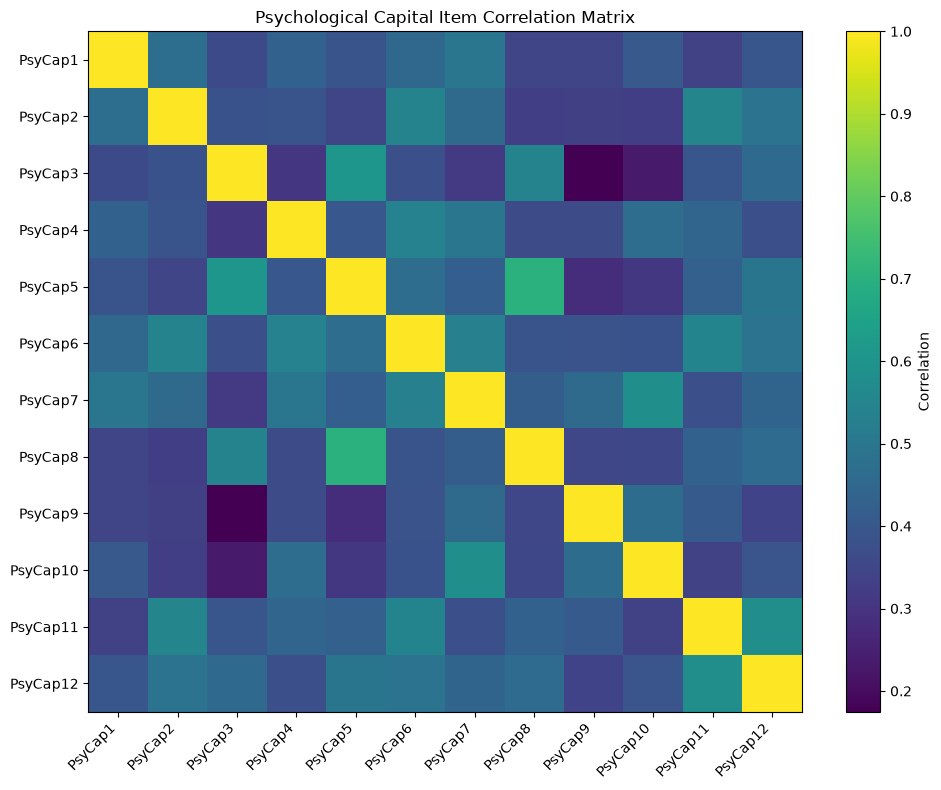

In [24]:
plt.figure(
    figsize=(10, 8)
)

correlation_matrix = (
    df[PSYCAP_ITEMS]
    .corr()
)

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Correlation"
)

plt.xticks(
    range(
        len(PSYCAP_ITEMS)
    ),
    PSYCAP_ITEMS,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(
        len(PSYCAP_ITEMS)
    ),
    PSYCAP_ITEMS
)

plt.title(
    "Psychological Capital Item Correlation Matrix"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "PsyCap_Item_Correlation_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Bootstrap Reliability Validation

Bootstrap resampling is used to assess the uncertainty of Cronbach's Alpha estimates.

For each construct, respondents are sampled with replacement multiple times and Cronbach's Alpha is recalculated.

The empirical 2.5th and 97.5th percentiles of the bootstrap distribution are reported as a 95% bootstrap interval.

Bootstrap Alpha Function

In [25]:
def bootstrap_alpha(
    data,
    n_bootstrap=1000,
    random_state=42
):

    rng = np.random.default_rng(
        random_state
    )

    data = (
        data
        .dropna()
        .reset_index(
            drop=True
        )
    )

    n_rows = len(
        data
    )

    bootstrap_alphas = []

    for _ in range(
        n_bootstrap
    ):

        indices = rng.integers(
            0,
            n_rows,
            size=n_rows
        )

        sample = (
            data
            .iloc[
                indices
            ]
        )

        alpha = cronbach_alpha(
            sample
        )

        if np.isfinite(
            alpha
        ):
            bootstrap_alphas.append(
                alpha
            )

    bootstrap_alphas = np.array(
        bootstrap_alphas
    )

    return {

        "Bootstrap_Mean_Alpha":
            float(
                bootstrap_alphas.mean()
            ),

        "CI_2.5":
            float(
                np.percentile(
                    bootstrap_alphas,
                    2.5
                )
            ),

        "CI_97.5":
            float(
                np.percentile(
                    bootstrap_alphas,
                    97.5
                )
            ),

        "Bootstrap_Samples":
            int(
                len(
                    bootstrap_alphas
                )
            )
    }

Bootstrap PsyCap Constructs

In [26]:
bootstrap_results = []

for construct, items in (
    PSYCAP_CONSTRUCTS.items()
):

    original_alpha = cronbach_alpha(
        df[items]
    )

    bootstrap = bootstrap_alpha(
        df[items],
        n_bootstrap=1000,
        random_state=42
    )

    bootstrap_results.append({

        "Construct": construct,

        "Original_Alpha":
            original_alpha,

        **bootstrap
    })


bootstrap_psycap_df = pd.DataFrame(
    bootstrap_results
)

bootstrap_psycap_df

,Construct,Original_Alpha,Bootstrap_Mean_Alpha,CI_2.5,CI_97.5,Bootstrap_Samples
0,Hope,0.664161,0.659045,0.553203,0.741644,1000
1,Optimism,0.722843,0.717343,0.636564,0.783579,1000
2,Resilience,0.661146,0.655284,0.569630,0.729803,1000
3,Self-Efficacy,0.701764,0.698310,0.629426,0.756060,1000


Bootstrap Overall PsyCap

In [27]:
overall_psycap_bootstrap = (
    bootstrap_alpha(
        df[PSYCAP_ITEMS],
        n_bootstrap=1000,
        random_state=42
    )
)

overall_psycap_bootstrap

{'Bootstrap_Mean_Alpha': 0.8922419988362824,
 'CI_2.5': 0.860323977404349,
 'CI_97.5': 0.9183198498443076,
 'Bootstrap_Samples': 1000}

Bootstrap Overall Employability

In [28]:
overall_evs_bootstrap = (
    bootstrap_alpha(
        df[EVS_ITEMS],
        n_bootstrap=1000,
        random_state=42
    )
)

overall_evs_bootstrap

{'Bootstrap_Mean_Alpha': 0.8985257807839847,
 'CI_2.5': 0.8754044254962559,
 'CI_97.5': 0.9197302487788477,
 'Bootstrap_Samples': 1000}

Reliability Decision Table

In [29]:
reliability_decision = (
    psycap_reliability_df
    .copy()
)

reliability_decision[
    "Decision"
] = np.where(

    reliability_decision[
        "Cronbach_Alpha"
    ] >= 0.70,

    "RETAIN",

    "REVIEW"
)

reliability_decision

,Construct,Number_of_Items,Cronbach_Alpha,Interpretation,Decision
0,Hope,3,0.664161,Questionable,REVIEW
1,Optimism,3,0.722843,Acceptable,RETAIN
2,Resilience,3,0.661146,Questionable,REVIEW
3,Self-Efficacy,3,0.701764,Acceptable,RETAIN


Add Diagnostic Flags

In [30]:
psycap_item_diagnostics[
    "Item_Total_Flag"
] = np.where(

    psycap_item_diagnostics[
        "Corrected_Item_Total_Correlation"
    ] >= 0.30,

    "OK",

    "REVIEW"
)


psycap_item_diagnostics[
    "Deletion_Flag"
] = np.where(

    psycap_item_diagnostics[
        "Alpha_Change"
    ] > 0.05,

    "REVIEW",

    "OK"
)


psycap_item_diagnostics

,Construct,Item,Corrected_Item_Total_Correlation,Interpretation,Original_Alpha,Alpha_If_Item_Deleted,Alpha_Change,Item_Total_Flag,Deletion_Flag
0,Hope,PsyCap1,0.497937,Acceptable,0.664161,0.550627,-0.113534,OK,OK
1,Hope,PsyCap2,0.511549,Strong,0.664161,0.520671,-0.143489,OK,OK
2,Hope,PsyCap3,0.433895,Acceptable,0.664161,0.641061,-0.023099,OK,OK
3,Optimism,PsyCap4,0.543534,Strong,0.722843,0.637265,-0.085579,OK,OK
4,Optimism,PsyCap5,0.495700,Acceptable,0.722843,0.700327,-0.022517,OK,OK
5,Optimism,PsyCap6,0.599792,Strong,0.722843,0.566584,-0.156260,OK,OK
6,Resilience,PsyCap7,0.533887,Strong,0.661146,0.519134,-0.142012,OK,OK
7,Resilience,PsyCap8,0.441702,Acceptable,0.661146,0.608849,-0.052296,OK,OK
8,Resilience,PsyCap9,0.472358,Acceptable,0.661146,0.576045,-0.085100,OK,OK
9,Self-Efficacy,PsyCap10,0.409052,Acceptable,0.701764,0.733460,0.031695,OK,OK


Overall Validation Summary

In [31]:
all_psycap_alpha_ok = bool(
    (
        psycap_reliability_df[
            "Cronbach_Alpha"
        ]
        >= 0.70
    )
    .all()
)


all_item_total_ok = bool(
    (
        psycap_item_diagnostics[
            "Corrected_Item_Total_Correlation"
        ]
        >= 0.30
    )
    .all()
)


overall_psycap_ok = bool(
    overall_psycap_alpha
    >= 0.70
)


overall_evs_ok = bool(
    overall_evs_alpha
    >= 0.70
)


validation_summary = pd.DataFrame({

    "Reliability_Check": [

        "Overall Psychological Capital",

        "All PsyCap construct alphas",

        "PsyCap corrected item-total correlations",

        "Overall Employability",

        "Bootstrap analysis completed"
    ],

    "Status": [

        (
            "PASS"
            if overall_psycap_ok
            else "REVIEW"
        ),

        (
            "PASS"
            if all_psycap_alpha_ok
            else "REVIEW"
        ),

        (
            "PASS"
            if all_item_total_ok
            else "REVIEW"
        ),

        (
            "PASS"
            if overall_evs_ok
            else "REVIEW"
        ),

        "PASS"
    ]
})

validation_summary

,Reliability_Check,Status
0,Overall Psychological Capital,PASS
1,All PsyCap construct alphas,REVIEW
2,PsyCap corrected item-total correlations,PASS
3,Overall Employability,PASS
4,Bootstrap analysis completed,PASS


Save Main Reliability Results

In [32]:
reliability_summary.to_csv(
    REPORT_DIR
    / "Reliability_Summary.csv",
    index=False
)

psycap_item_diagnostics.to_csv(
    REPORT_DIR
    / "PsyCap_Item_Diagnostics.csv",
    index=False
)

inter_item_summary_df.to_csv(
    REPORT_DIR
    / "PsyCap_Inter_Item_Summary.csv",
    index=False
)

bootstrap_psycap_df.to_csv(
    REPORT_DIR
    / "PsyCap_Bootstrap_Reliability.csv",
    index=False
)

validation_summary.to_csv(
    REPORT_DIR
    / "Reliability_Validation_Summary.csv",
    index=False
)

print(
    "Reliability reports saved successfully."
)

Reliability reports saved successfully.


Save Overall Bootstrap Summary

In [33]:
overall_bootstrap_summary = pd.DataFrame([
    {
        "Scale":
            "Overall Psychological Capital",

        "Original_Alpha":
            overall_psycap_alpha,

        **overall_psycap_bootstrap
    },

    {
        "Scale":
            "Overall Employability",

        "Original_Alpha":
            overall_evs_alpha,

        **overall_evs_bootstrap
    }
])


overall_bootstrap_summary.to_csv(
    REPORT_DIR
    / "Overall_Bootstrap_Reliability.csv",
    index=False
)

overall_bootstrap_summary

,Scale,Original_Alpha,Bootstrap_Mean_Alpha,CI_2.5,CI_97.5,Bootstrap_Samples
0,Overall Psychological Capital,0.894527,0.892242,0.860324,0.91832,1000
1,Overall Employability,0.900229,0.898526,0.875404,0.91973,1000


Print Final Reliability Overview

In [34]:
print(
    "PHASE 03 — STEP 02 RELIABILITY OVERVIEW"
)

print(
    "\nPsychological Capital constructs:"
)

print(
    psycap_reliability_df[
        [
            "Construct",
            "Cronbach_Alpha",
            "Interpretation"
        ]
    ]
    .to_string(
        index=False
    )
)


print(
    "\nOverall PsyCap Alpha:",
    round(
        overall_psycap_alpha,
        4
    )
)


print(
    "Overall EVS Alpha:",
    round(
        overall_evs_alpha,
        4
    )
)


print(
    "\nValidation:"
)

print(
    validation_summary
    .to_string(
        index=False
    )
)

PHASE 03 — STEP 02 RELIABILITY OVERVIEW

Psychological Capital constructs:
    Construct  Cronbach_Alpha Interpretation
         Hope        0.664161   Questionable
     Optimism        0.722843     Acceptable
   Resilience        0.661146   Questionable
Self-Efficacy        0.701764     Acceptable

Overall PsyCap Alpha: 0.8945
Overall EVS Alpha: 0.9002

Validation:
                       Reliability_Check Status
           Overall Psychological Capital   PASS
             All PsyCap construct alphas REVIEW
PsyCap corrected item-total correlations   PASS
                   Overall Employability   PASS
            Bootstrap analysis completed   PASS


## Step 02 Conclusion

Reliability analysis was conducted to evaluate the internal consistency of the Phase 03 Psychological Capital and Employability measures.

Cronbach's Alpha was calculated for the four Psychological Capital dimensions: Hope, Optimism, Resilience, and Self-Efficacy, together with the overall Psychological Capital scale.

Corrected item–total correlations and Cronbach's Alpha if item deleted were examined to identify potentially inconsistent or redundant items without relying solely on the overall Alpha coefficient.

Inter-item correlations were also evaluated to examine consistency among items within each construct.

Bootstrap resampling was used to assess the uncertainty of the reliability estimates and provide empirical reliability intervals.

The Employability scale was evaluated using the same internal-consistency framework. Cronbach's Alpha was not calculated for Environmental Monitoring because it is represented by a single item.

The reliability evidence was used to determine whether the questionnaire constructs were sufficiently consistent for subsequent statistical and machine-learning analysis.

## Additional Reliability Validation

To strengthen the internal-consistency assessment, additional reliability evidence was examined using:

- McDonald's Omega
- Split-half reliability
- Spearman-Brown corrected reliability
- Construct-level correlations
- Consolidated reliability evidence

These additional checks complement Cronbach's Alpha and provide a broader assessment of questionnaire consistency.

In [39]:
from sklearn.decomposition import FactorAnalysis
from sklearn.preprocessing import StandardScaler

Omega Function

In [42]:
def mcdonald_omega(data):

    data = (
        data
        .dropna()
        .astype(float)
    )

    # Standardize questionnaire items
    scaler = StandardScaler()

    standardized_data = scaler.fit_transform(
        data
    )

    # Fit a one-factor model
    factor_model = FactorAnalysis(
        n_components=1,
        random_state=42
    )

    factor_model.fit(
        standardized_data
    )

    # Factor loadings
    loadings = (
        factor_model
        .components_[0]
    )

    # Factor direction is arbitrary.
    # Reverse the sign if most loadings are negative.
    if np.sum(loadings) < 0:
        loadings = -loadings

    # Unique/error variances
    uniquenesses = (
        factor_model
        .noise_variance_
    )

    numerator = (
        np.sum(loadings) ** 2
    )

    denominator = (
        numerator
        +
        np.sum(uniquenesses)
    )

    omega = (
        numerator
        /
        denominator
    )

    return float(
        omega
    )

Calculate Omega for PsyCap Constructs

In [43]:
omega_results = []

for construct, items in (
    PSYCAP_CONSTRUCTS.items()
):

    omega = mcdonald_omega(
        df[items]
    )

    omega_results.append({

        "Construct": construct,

        "McDonalds_Omega":
            omega,

        "Interpretation":
            interpret_alpha(
                omega
            )
    })


omega_df = pd.DataFrame(
    omega_results
)

omega_df

,Construct,McDonalds_Omega,Interpretation
0,Hope,0.676441,Questionable
1,Optimism,0.731485,Acceptable
2,Resilience,0.679120,Questionable
3,Self-Efficacy,0.715249,Acceptable


Overall PsyCap Omega

In [44]:
overall_psycap_omega = (
    mcdonald_omega(
        df[PSYCAP_ITEMS]
    )
)

print(
    "Overall PsyCap Omega:",
    overall_psycap_omega
)

print(
    "Interpretation:",
    interpret_alpha(
        overall_psycap_omega
    )
)

Overall PsyCap Omega: 0.8971592939043487
Interpretation: Good


Overall EVS Omega

In [45]:
overall_evs_omega = (
    mcdonald_omega(
        df[EVS_ITEMS]
    )
)

print(
    "Overall EVS Omega:",
    overall_evs_omega
)

print(
    "Interpretation:",
    interpret_alpha(
        overall_evs_omega
    )
)

Overall EVS Omega: 0.9046713151632226
Interpretation: Excellent


2. Split-Half Reliability
Sinhala explanation

Questionnaire items දෙකට split කරලා halves දෙක same concept measure කරනවද බලනවා.

Then Spearman-Brown correction apply කරනවා.

In [46]:
def split_half_reliability(data):

    data = (
        data
        .dropna()
        .astype(float)
    )

    columns = list(
        data.columns
    )

    first_half = columns[
        ::2
    ]

    second_half = columns[
        1::2
    ]

    first_score = (
        data[
            first_half
        ]
        .sum(
            axis=1
        )
    )

    second_score = (
        data[
            second_half
        ]
        .sum(
            axis=1
        )
    )

    correlation = (
        first_score
        .corr(
            second_score
        )
    )

    spearman_brown = (
        2 * correlation
        /
        (
            1
            +
            correlation
        )
    )

    return {
        "Half_Correlation":
            float(
                correlation
            ),

        "Spearman_Brown":
            float(
                spearman_brown
            )
    }

Apply to PsyCap Constructs

In [47]:
split_half_results = []

for construct, items in (
    PSYCAP_CONSTRUCTS.items()
):

    result = (
        split_half_reliability(
            df[items]
        )
    )

    split_half_results.append({

        "Construct": construct,

        "Half_Correlation":
            result[
                "Half_Correlation"
            ],

        "Spearman_Brown":
            result[
                "Spearman_Brown"
            ]
    })


split_half_df = pd.DataFrame(
    split_half_results
)

split_half_df

,Construct,Half_Correlation,Spearman_Brown
0,Hope,0.511549,0.676854
1,Optimism,0.495700,0.662833
2,Resilience,0.441702,0.612751
3,Self-Efficacy,0.563195,0.720569


Overall Split-Half Reliability

In [48]:
overall_psycap_split = (
    split_half_reliability(
        df[PSYCAP_ITEMS]
    )
)

overall_evs_split = (
    split_half_reliability(
        df[EVS_ITEMS]
    )
)

print(
    "Overall PsyCap:",
    overall_psycap_split
)

print(
    "Overall EVS:",
    overall_evs_split
)

Overall PsyCap: {'Half_Correlation': 0.8590021476943688, 'Spearman_Brown': 0.9241540132266635}
Overall EVS: {'Half_Correlation': 0.889589437748152, 'Spearman_Brown': 0.941569020208207}


3. Construct Correlation Check
Sinhala explanation

PsyCap constructs එකිනෙකට completely unrelated වෙන්නත් බැහැ.

At the same time extremely high correlation තිබ්බොත් constructs separate dimensions නෙවෙයි කියන issue එකක් එන්න පුළුවන්.

In [49]:
PSYCAP_CONSTRUCT_COLUMNS = [
    "Hope_avg",
    "Optimism_avg",
    "Resilience_avg",
    "SelfEfficacy_avg"
]

construct_correlation_matrix = (
    df[
        PSYCAP_CONSTRUCT_COLUMNS
    ]
    .corr()
)

construct_correlation_matrix

,Hope_avg,Optimism_avg,Resilience_avg,SelfEfficacy_avg
Hope_avg,1.000000,0.686607,0.601453,0.652746
Optimism_avg,0.686607,1.000000,0.693565,0.688272
Resilience_avg,0.601453,0.693565,1.000000,0.686397
SelfEfficacy_avg,0.652746,0.688272,0.686397,1.000000


Check Extremely High Correlations

In [50]:
high_correlation_pairs = []

for i in range(
    len(
        PSYCAP_CONSTRUCT_COLUMNS
    )
):

    for j in range(
        i + 1,
        len(
            PSYCAP_CONSTRUCT_COLUMNS
        )
    ):

        feature_1 = (
            PSYCAP_CONSTRUCT_COLUMNS[
                i
            ]
        )

        feature_2 = (
            PSYCAP_CONSTRUCT_COLUMNS[
                j
            ]
        )

        correlation = (
            construct_correlation_matrix
            .loc[
                feature_1,
                feature_2
            ]
        )

        high_correlation_pairs.append({

            "Construct_1":
                feature_1,

            "Construct_2":
                feature_2,

            "Correlation":
                correlation,

            "Potential_Redundancy":
                (
                    "REVIEW"
                    if abs(
                        correlation
                    ) >= 0.85
                    else "OK"
                )
        })


construct_correlation_pairs = (
    pd.DataFrame(
        high_correlation_pairs
    )
)

construct_correlation_pairs

,Construct_1,Construct_2,Correlation,Potential_Redundancy
0,Hope_avg,Optimism_avg,0.686607,OK
1,Hope_avg,Resilience_avg,0.601453,OK
2,Hope_avg,SelfEfficacy_avg,0.652746,OK
3,Optimism_avg,Resilience_avg,0.693565,OK
4,Optimism_avg,SelfEfficacy_avg,0.688272,OK
5,Resilience_avg,SelfEfficacy_avg,0.686397,OK


4. Final Evidence Table

මේක Step 02 එකේ strongest summary table එක.

Cell L — Merge Alpha, Omega, Item-Total and Inter-Item Results

In [51]:
minimum_item_total = (

    psycap_item_diagnostics

    .groupby(
        "Construct"
    )[
        "Corrected_Item_Total_Correlation"
    ]

    .min()

    .reset_index()

    .rename(
        columns={
            "Corrected_Item_Total_Correlation":
                "Minimum_Item_Total_Correlation"
        }
    )
)


final_reliability_evidence = (

    psycap_reliability_df

    .merge(
        omega_df[
            [
                "Construct",
                "McDonalds_Omega"
            ]
        ],
        on="Construct",
        how="left"
    )

    .merge(
        inter_item_summary_df[
            [
                "Construct",
                "Mean_Inter_Item_Correlation"
            ]
        ],
        on="Construct",
        how="left"
    )

    .merge(
        minimum_item_total,
        on="Construct",
        how="left"
    )

    .merge(
        split_half_df[
            [
                "Construct",
                "Spearman_Brown"
            ]
        ],
        on="Construct",
        how="left"
    )
)

Add Final Decision

In [52]:
def final_reliability_decision(
    row
):

    alpha = (
        row[
            "Cronbach_Alpha"
        ]
    )

    omega = (
        row[
            "McDonalds_Omega"
        ]
    )

    item_total = (
        row[
            "Minimum_Item_Total_Correlation"
        ]
    )

    if (
        alpha >= 0.70
        and
        omega >= 0.70
        and
        item_total >= 0.30
    ):
        return "RETAIN"

    elif (
        item_total >= 0.30
        and
        omega >= 0.60
    ):
        return "RETAIN WITH NOTE"

    else:
        return "REVIEW"


final_reliability_evidence[
    "Final_Decision"
] = (

    final_reliability_evidence
    .apply(
        final_reliability_decision,
        axis=1
    )
)

final_reliability_evidence

,Construct,Number_of_Items,Cronbach_Alpha,Interpretation,McDonalds_Omega,Mean_Inter_Item_Correlation,Minimum_Item_Total_Correlation,Spearman_Brown,Final_Decision
0,Hope,3,0.664161,Questionable,0.676441,0.406249,0.433895,0.676854,RETAIN WITH NOTE
1,Optimism,3,0.722843,Acceptable,0.731485,0.469216,0.495700,0.662833,RETAIN
2,Resilience,3,0.661146,Questionable,0.679120,0.409293,0.441702,0.612751,RETAIN WITH NOTE
3,Self-Efficacy,3,0.701764,Acceptable,0.715249,0.435849,0.409052,0.720569,RETAIN


Save Strengthened Reliability Results

In [53]:
omega_df.to_csv(
    REPORT_DIR
    / "PsyCap_McDonalds_Omega.csv",
    index=False
)

split_half_df.to_csv(
    REPORT_DIR
    / "PsyCap_Split_Half_Reliability.csv",
    index=False
)

construct_correlation_matrix.to_csv(
    REPORT_DIR
    / "PsyCap_Construct_Correlation_Matrix.csv"
)

construct_correlation_pairs.to_csv(
    REPORT_DIR
    / "PsyCap_Construct_Correlation_Check.csv",
    index=False
)

final_reliability_evidence.to_csv(
    REPORT_DIR
    / "Final_Reliability_Evidence.csv",
    index=False
)

print(
    "Additional reliability evidence saved."
)

Additional reliability evidence saved.


Updated Validation Summary

In [54]:
omega_ok = bool(
    (
        omega_df[
            "McDonalds_Omega"
        ]
        >= 0.60
    )
    .all()
)


split_half_ok = bool(
    (
        split_half_df[
            "Spearman_Brown"
        ]
        >= 0.60
    )
    .all()
)


no_extreme_construct_overlap = bool(
    (
        construct_correlation_pairs[
            "Potential_Redundancy"
        ]
        ==
        "OK"
    )
    .all()
)


strengthened_validation_summary = pd.DataFrame({

    "Reliability_Check": [

        "Overall Psychological Capital Alpha",

        "Overall Psychological Capital Omega",

        "Corrected item-total correlations",

        "McDonald's Omega construct validation",

        "Split-half reliability",

        "Construct redundancy check",

        "Bootstrap reliability",

        "Overall Employability reliability"
    ],

    "Status": [

        (
            "PASS"
            if overall_psycap_alpha >= 0.70
            else "REVIEW"
        ),

        (
            "PASS"
            if overall_psycap_omega >= 0.70
            else "REVIEW"
        ),

        (
            "PASS"
            if all_item_total_ok
            else "REVIEW"
        ),

        (
            "PASS"
            if omega_ok
            else "REVIEW"
        ),

        (
            "PASS"
            if split_half_ok
            else "REVIEW"
        ),

        (
            "PASS"
            if no_extreme_construct_overlap
            else "REVIEW"
        ),

        "PASS",

        (
            "PASS"
            if overall_evs_alpha >= 0.70
            else "REVIEW"
        )
    ]
})

strengthened_validation_summary

,Reliability_Check,Status
0,Overall Psychological Capital Alpha,PASS
1,Overall Psychological Capital Omega,PASS
2,Corrected item-total correlations,PASS
3,McDonald's Omega construct validation,PASS
4,Split-half reliability,PASS
5,Construct redundancy check,PASS
6,Bootstrap reliability,PASS
7,Overall Employability reliability,PASS


Save final validation summary

In [55]:
strengthened_validation_summary.to_csv(
    REPORT_DIR
    / "Strengthened_Reliability_Validation_Summary.csv",
    index=False
)

strengthened_validation_summary

,Reliability_Check,Status
0,Overall Psychological Capital Alpha,PASS
1,Overall Psychological Capital Omega,PASS
2,Corrected item-total correlations,PASS
3,McDonald's Omega construct validation,PASS
4,Split-half reliability,PASS
5,Construct redundancy check,PASS
6,Bootstrap reliability,PASS
7,Overall Employability reliability,PASS


## Strengthened Reliability Conclusion

The Phase 03 reliability assessment was strengthened using multiple complementary internal-consistency measures.

Cronbach's Alpha, McDonald's Omega, corrected item-total correlations, alpha-if-item-deleted analysis, inter-item correlations, split-half reliability, and bootstrap reliability estimates were examined.

The overall Psychological Capital scale demonstrated strong internal consistency. While some individual PsyCap dimensions showed slightly lower Cronbach's Alpha values, the item-level diagnostics, complementary Omega estimates, and inter-item relationships were considered together rather than relying on a single threshold.

Construct-level correlations were also examined to identify potential redundancy between the four Psychological Capital dimensions.

Based on the combined statistical evidence and theoretical relevance of the questionnaire items, the retained Psychological Capital items were considered suitable for subsequent descriptive, correlation, regression, and machine-learning analyses. Any borderline construct-level reliability values are reported transparently as a limitation.